# Figure 3 Supplement 4: Trial-to-trial variability and history dependence of the bound

Two questions about the trial-by-trial bound measurements, each answered by
comparing the real data with data simulated from each subject's stopping-model
fit, on the same trials in the same order and measured with the same pipeline:

**A — How much of the variability in the measured bounds is real?** The SD of
each subject's measured |bound| across trials (data, black) against the SD
expected without bound variability: the model with its trial-to-trial bound
variability removed (`bound_cv` set to `NO_VAR_CV`), which keeps the bound's
time course, the discrete pigeon steps, guesses, lapses, sensory noise and
non-decision time. Points above the identity line have variability beyond
these sources. In practice the measured spread is dominated by measurement
(step overshoot, extra steps during the non-decision time, sensory noise), so
it says little about the fitted bound variability, which the model identifies
from other features of the data (see Supplement 1 for its recovery). Blue: the full
model (with its fitted bound variability) against the same abscissa. Model SDs
are means over `SIM_REPS` simulated repetitions.

**B — Does the bound depend on the previous trial's outcome?** For each subject,
the change in |bound| on the trial after an error, as a fraction of the
subject's median |bound| in that block, controlling for the previous trial's
|bound| (`pigeon.adaptation.get_post_error_bound_effect`; the control keeps
carryover of the bound, together with errors being more common after low
bounds, from counting as a post-error effect). The model has no trial history,
so its coefficients show what noise alone produces. Black points: subjects;
black line: median. Light blue band: central 95% of individual subjects'
coefficients in the simulations; dark blue band: central 95% of the
across-subject median over simulated repetitions. P values: two-sided, data
median vs. the simulated medians.

Columns: OL low-SNR blocks 1–3 (the error penalty differs by block: none,
coins, steps). Trials serving as trial n: the standard filter
(`get_good_trial_array`: DT ≥ 2, trial_number ≥ 10 and the adaptation
exclusion, no wall hit, RT cutoff), finite nonzero bound, raw positions (no
bias correction) for data and model. A: subjects need ≥ `MIN_TRIALS` such
trials. B: subjects need ≥ `MIN_POST_ERROR` post-error trials; when the
previous trial's bound is unmeasurable (e.g. a one-step guess) the subject's
mean is imputed for the control (counts printed). Subject-blocks whose plateau
sits at a fit limit are left out (counts printed).

**Caption only: lag-1 autocorrelation.** The correlation between consecutive
measured |bound| values, data vs. the full model (same subjects as A): the
median per-subject difference from the model's mean over repetitions, the
median of each subject's percentile among the model's repetitions, and a
paired Wilcoxon signed-rank p (data vs. model mean). The model has no trial
history, so a higher data value is carryover from one trial to the next.


In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.adaptation import get_post_error_bound_effect, get_sequential_bound_stats
from pigeon.data import get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, CONDITION_LABELS, DATA_COLOR, MODEL_COLOR, add_panel_label,
                             add_row_xlabel, format_p, use_figure_style)
from pigeon.stopping import (get_plateau_at_limit, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

In [ ]:
SIM_REPS = 100
SIM_SEED = 13
NO_VAR_CV = 1e-3      # bound_cv for the measurement-only model (0 itself is not a valid gamma CV)
MIN_TRIALS = 20
MIN_POST_ERROR = 3
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {f'B{b}': CONDITION_LABELS[b] for b in (1, 2, 3)}

trials_all = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
trials = trials_all[trials_all.condition.isin(BLOCKS)].copy()
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[(fits.task == 'OL') & fits.group.isin(BLOCKS)]
rng = np.random.default_rng(SIM_SEED)
sims = {}
for name, f in {'full': fits, 'no_var': fits.assign(bound_cv=NO_VAR_CV)}.items():
    s = simulate_stopping_data_table(trials, f, group_col='condition', num_reps=SIM_REPS, rng=rng)
    sims[name] = infer_bounds_like_data(s)    # keeps each simulated trial's real trial_number

def _with_measured(t):
    """All trials, with abs_bound set to NaN where the trial's bound is not used."""
    lg = get_good_trial_array(t, min_dt=2) & np.isfinite(t.bound) & (t.bound != 0)
    return t.assign(abs_bound=t.bound.abs().where(lg))

real_t = _with_measured(trials)
sim_t = {k: _with_measured(v) for k, v in sims.items()}
KEYS = ['subject_index', 'condition']

at_limit = pd.MultiIndex.from_frame(fits.loc[get_plateau_at_limit(fits), ['subject_index', 'group']])

# A: SDs of the measured |bound| (and, for the caption, the lag-1 autocorrelation)
sd = get_sequential_bound_stats(real_t, group_cols=KEYS, min_trials=MIN_TRIALS)[['n_trials', 'sd', 'lag1_r']]
sim_stats = {k: get_sequential_bound_stats(t, group_cols=KEYS + ['rep'], min_trials=MIN_TRIALS)
             for k, t in sim_t.items()}
for k, s in sim_stats.items():
    sd[f'sd_{k}'] = s.sd.groupby(level=KEYS).mean()
lag1_sim = sim_stats['full'].lag1_r.unstack('rep')
sd['lag1_r_model'] = lag1_sim.mean(axis=1)
sd['lag1_percentile'] = lag1_sim.lt(sd.lag1_r, axis=0).mean(axis=1)
l_lim = sd.index.isin(at_limit)
print(f'excluded {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: {list(sd.index[l_lim])}')
sd = sd[~l_lim]

# B: post-error effect
pe_real = get_post_error_bound_effect(real_t, group_cols=KEYS, min_post_error=MIN_POST_ERROR)
pe_real = pe_real[~pe_real.index.isin(at_limit)]
pe_sim = get_post_error_bound_effect(sim_t['full'], group_cols=KEYS + ['rep'], min_post_error=MIN_POST_ERROR)
pe_sim = pe_sim[~pe_sim.droplevel('rep').index.isin(at_limit)]
# Simulated subject-blocks use only the subjects that enter the real comparison
pe_sim = pe_sim[pe_sim.droplevel('rep').index.isin(pe_real.dropna(subset=['post_error_effect']).index)]

rows = []
for b in BLOCKS:
    g = sd.xs(b, level='condition').dropna()
    r = pe_real.xs(b, level='condition')
    x = r.post_error_effect.dropna()
    sim_med = pe_sim.xs(b, level='condition').post_error_effect.groupby(level='rep').median()
    dev = np.abs(sim_med - sim_med.mean())
    p = (1 + (dev >= abs(x.median() - sim_med.mean())).sum()) / (1 + len(sim_med))
    rows.append({'block': b, 'A subjects': len(g),
                 'SD data': g.sd.median(), 'SD measurement only': g.sd_no_var.median(), 'SD full model': g.sd_full.median(),
                 'fraction of data variance beyond measurement': (1 - g.sd_no_var ** 2 / g.sd ** 2).median(),
                 'data SD > measurement-only SD': f'{int((g.sd > g.sd_no_var).sum())}/{len(g)}',
                 'Wilcoxon p (data vs. full model SD)': scipy.stats.wilcoxon(g.sd, g.sd_full).pvalue,
                 'B subjects': len(x), f'B excluded (< {MIN_POST_ERROR} post-error trials)': int(r.post_error_effect.isna().sum()),
                 'median post-error trials': r.n_post_error[x.index].median(),
                 'prev bound imputed (fraction of trials)': r.n_prev_imputed[x.index].sum() / r.n_trials[x.index].sum(),
                 'post-error effect, median': x.median(), 'simulated medians, 95%': f'[{sim_med.quantile(.025):.3f}, {sim_med.quantile(.975):.3f}]',
                 'p (vs. simulated medians)': p,
                 'lag-1 r, data − model (median)': (g.lag1_r - g.lag1_r_model).median(),
                 'lag-1 r, percentile in model (median)': g.lag1_percentile.median(),
                 'lag-1 r, Wilcoxon p (data vs. model)': scipy.stats.wilcoxon(g.lag1_r, g.lag1_r_model).pvalue})
    print(f'{b}: {int((sd.xs(b, level="condition").n_trials < MIN_TRIALS).sum())} subjects with < {MIN_TRIALS} usable trials (no SD)')
summary = pd.DataFrame(rows).set_index('block').T
display(summary)


B1: A, 0 of 52 subjects with an SD outside (0.05, 0.25) (not shown)
B1: B, 0 below and 2 above (-0.6, 0.6) of 53, drawn at the limit
B2: A, 0 of 52 subjects with an SD outside (0.05, 0.25) (not shown)
B2: B, 0 below and 0 above (-0.6, 0.6) of 50, drawn at the limit
B3: A, 0 of 43 subjects with an SD outside (0.05, 0.25) (not shown)
B3: B, 0 below and 1 above (-0.6, 0.6) of 42, drawn at the limit


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


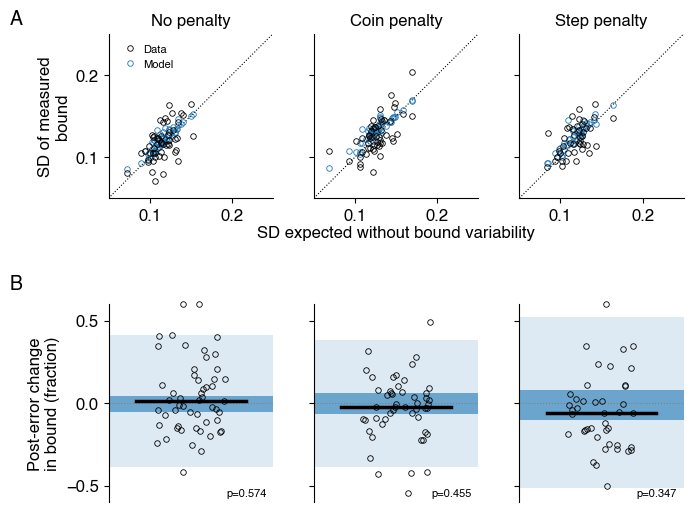

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S04.pdf (+ .png)


In [3]:
use_figure_style()
SD_LIM = (0.05, 0.25)
PE_LIM = (-0.6, 0.6)

fig = plt.figure(figsize=(17.6 * CM, 14 * CM))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.25, left=0.15, right=0.98, bottom=0.06, top=0.94)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(2)])
jitter = np.random.default_rng(0)
for c, b in enumerate(BLOCKS):
    # A
    ax = axes[0, c]
    g = sd.xs(b, level='condition').dropna()
    ax.plot(SD_LIM, SD_LIM, 'k:', lw=0.8)
    ax.plot(g.sd_no_var, g.sd_full, 'o', color=MODEL_COLOR, mfc='none', ms=4, mew=0.6, label='Model')
    ax.plot(g.sd_no_var, g.sd, 'o', color=DATA_COLOR, mfc='none', ms=4, mew=0.6, label='Data')
    n_out = int((~g[['sd', 'sd_full', 'sd_no_var']].apply(lambda v: v.between(*SD_LIM)).all(axis=1)).sum())
    print(f'{b}: A, {n_out} of {len(g)} subjects with an SD outside {SD_LIM} (not shown)')
    ax.set_xlim(SD_LIM)
    ax.set_ylim(SD_LIM)
    ax.set_xticks([0.1, 0.2])
    ax.set_yticks([0.1, 0.2])
    ax.set_box_aspect(1)
    ax.set_title(BLOCK_TITLES[b])
    # B
    ax = axes[1, c]
    x = pe_real.xs(b, level='condition').post_error_effect.dropna()
    s = pe_sim.xs(b, level='condition').post_error_effect.dropna()
    sim_med = s.groupby(level='rep').median()
    ax.axhspan(*s.quantile([.025, .975]), color=MODEL_COLOR, alpha=0.15, lw=0)
    ax.axhspan(*sim_med.quantile([.025, .975]), color=MODEL_COLOR, alpha=0.6, lw=0)
    ax.axhline(0, color='0.5', ls=':', lw=0.8)
    ax.plot(jitter.uniform(-0.25, 0.25, len(x)), x.clip(*PE_LIM), 'o', color=DATA_COLOR, mfc='none', ms=4, mew=0.6,
            clip_on=False)
    print(f'{b}: B, {int((x < PE_LIM[0]).sum())} below and {int((x > PE_LIM[1]).sum())} above {PE_LIM} of {len(x)}, '
          'drawn at the limit')
    ax.plot([-0.4, 0.4], [x.median()] * 2, '-', color=DATA_COLOR, lw=2.5)
    p = summary.loc['p (vs. simulated medians)', b]
    ax.text(0.96, 0.02, format_p(p), transform=ax.transAxes, ha='right', va='bottom', fontsize=FS_INSET)
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(PE_LIM)
    ax.set_xticks([])
    ax.spines['bottom'].set_visible(False)
    ax.set_yticks([-0.5, 0, 0.5])
    for r in range(2):
        axes[r, c].spines[['top', 'right']].set_visible(False)
        if c > 0:
            axes[r, c].set_yticklabels([])
axes[0, 0].set_ylabel('SD of measured\nbound')
h, l = axes[0, 0].get_legend_handles_labels()
axes[0, 0].legend(h[::-1], l[::-1], fontsize=FS_INSET, frameon=False, loc='upper left', handletextpad=0.2)
axes[1, 0].set_ylabel('Post-error change\nin bound (fraction)')

add_row_xlabel(fig, axes[0], 'SD expected without bound variability')
for r, letter in enumerate('AB'):
    add_panel_label(axes[r, 0], letter, dx=-0.6, dy=1.15)

out = FIGURES_DIR / 'Figure03_S04.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')
